# Projet 4 : Classifiez automatiquement des informations

## Analyse exploratoire des données (EDA)

Résultats attendus

Un DataFrame central, issu d’une jointure entre les fichiers de départ.

Des cellules au sein du notebook pour calculer des statistiques descriptives sur les fichiers de départ et le fichier central, dans l’objectif de faire ressortir des différences clés entre les employés.

Des cellules au sein du notebook pour générer des graphiques, dans l’objectif de faire ressortir des différences clés entre les employés.

### 1 - Chargement des librairies et des datasets bruts

In [36]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt 
from scipy.stats import zscore
import seaborn as sb
import numpy as np

In [4]:
DATA_RAW = Path("../Data/Raw")
DATA_PROCESSED = Path("../Data/Processed")

df_brut_eval = pd.read_csv(DATA_RAW / "extrait_eval.csv")
df_brut_sirh = pd.read_csv(DATA_RAW / "extrait_sirh.csv")
df_brut_sondage = pd.read_csv(DATA_RAW / "extrait_sondage.csv")

### 2 - Traitement pré-jointure

Comparaison des colonnes qui serviront de jointure.   
L'objectif est de s'assurer qu'elles sont strictement identiques 

In [5]:
# 1. On extrait les colonnes sous forme de Séries
col1 = df_brut_eval["eval_number"]
col2 = df_brut_sirh["id_employee"]
col3 = df_brut_sondage["code_sondage"]

# 2. On compare la première avec les deux autres
identiques = col1.equals(col2) and col1.equals(col3)
print(identiques)

False


Fichier : extrait_sondage.   
Renommage de la colonne code_sondage en id_employee

In [6]:
df_brut_sondage.rename(columns={'code_sondage': 'id_employee'}, inplace=True)

# Verification 
df_brut_sondage.columns

Index(['a_quitte_l_entreprise', 'nombre_participation_pee',
       'nb_formations_suivies', 'nombre_employee_sous_responsabilite',
       'id_employee', 'distance_domicile_travail', 'niveau_education',
       'domaine_etude', 'ayant_enfants', 'frequence_deplacement',
       'annees_depuis_la_derniere_promotion', 'annes_sous_responsable_actuel'],
      dtype='object')

Fichier : extrait_eval.   
Renommage de la colonne eval_number en id_employee

In [7]:
df_brut_eval.rename(columns={'eval_number': 'id_employee'}, inplace=True)

# Verification 
df_brut_eval.columns

Index(['satisfaction_employee_environnement', 'note_evaluation_precedente',
       'niveau_hierarchique_poste', 'satisfaction_employee_nature_travail',
       'satisfaction_employee_equipe',
       'satisfaction_employee_equilibre_pro_perso', 'id_employee',
       'note_evaluation_actuelle', 'heure_supplementaires',
       'augementation_salaire_precedente'],
      dtype='object')

Fichier : extrait_eval.   
Traitement des valeurs, suppression des "E_" au début de chaque valeur.    
Transformation de la colonne en numérique

In [8]:
# 'slicing' string. Tronque les 2 premiers caractères a chaque occurence de la Series 'id_employee'
df_brut_eval['id_employee'] = df_brut_eval['id_employee'].apply(lambda x: x[2:]) 

# Verification
df_brut_eval['id_employee'].head(12)

0      1
1      2
2      4
3      5
4      7
5      8
6     10
7     11
8     12
9     13
10    14
11    15
Name: id_employee, dtype: object

In [9]:
# Convertit le type de la array series de string vers numérique (par defaut Int64)
df_brut_eval['id_employee'] = pd.to_numeric(df_brut_eval['id_employee'])

# Verification
df_brut_eval.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 10 columns):
 #   Column                                     Non-Null Count  Dtype 
---  ------                                     --------------  ----- 
 0   satisfaction_employee_environnement        1470 non-null   int64 
 1   note_evaluation_precedente                 1470 non-null   int64 
 2   niveau_hierarchique_poste                  1470 non-null   int64 
 3   satisfaction_employee_nature_travail       1470 non-null   int64 
 4   satisfaction_employee_equipe               1470 non-null   int64 
 5   satisfaction_employee_equilibre_pro_perso  1470 non-null   int64 
 6   id_employee                                1470 non-null   int64 
 7   note_evaluation_actuelle                   1470 non-null   int64 
 8   heure_supplementaires                      1470 non-null   object
 9   augementation_salaire_precedente           1470 non-null   object
dtypes: int64(8), object(2)
memory usage:

### 3 - Création du dataset joint

Jointure entre df_brut_sirh et df_brut_sondage

In [10]:
df_join1 = df_brut_sirh.merge(df_brut_sondage, on="id_employee", how="left")

In [11]:
df_join1

,id_employee,age,genre,revenu_mensuel,statut_marital,departement,poste,nombre_experiences_precedentes,nombre_heures_travailless,annee_experience_totale,...,nombre_participation_pee,nb_formations_suivies,nombre_employee_sous_responsabilite,distance_domicile_travail,niveau_education,domaine_etude,ayant_enfants,frequence_deplacement,annees_depuis_la_derniere_promotion,annes_sous_responsable_actuel
0,1,41,F,5993,Célibataire,Commercial,Cadre Commercial,8,80,8,...,0,0,1,1,2,Infra & Cloud,Y,Occasionnel,0,5
1,2,49,M,5130,Marié(e),Consulting,Assistant de Direction,1,80,10,...,1,3,1,8,1,Infra & Cloud,Y,Frequent,1,7
2,4,37,M,2090,Célibataire,Consulting,Consultant,6,80,7,...,0,3,1,2,2,Autre,Y,Occasionnel,0,0
3,5,33,F,2909,Marié(e),Consulting,Assistant de Direction,1,80,8,...,0,3,1,3,4,Infra & Cloud,Y,Frequent,3,0
4,7,27,M,3468,Marié(e),Consulting,Consultant,9,80,6,...,1,3,1,2,1,Transformation Digitale,Y,Occasionnel,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,2061,36,M,2571,Marié(e),Consulting,Consultant,4,80,17,...,1,3,1,23,2,Transformation Digitale,Y,Frequent,0,3
1466,2062,39,M,9991,Marié(e),Consulting,Manager,4,80,9,...,1,5,1,6,1,Transformation Digitale,Y,Occasionnel,1,7
1467,2064,27,M,6142,Marié(e),Consulting,Tech Lead,1,80,6,...,1,0,1,4,3,Infra & Cloud,Y,Occasionnel,0,3
1468,2065,49,M,5390,Marié(e),Commercial,Cadre Commercial,2,80,17,...,0,3,1,2,3,Transformation Digitale,Y,Frequent,0,8


Jointure entre df_join1 et df_brut_eval

In [12]:
df_brut_join = df_join1.merge(df_brut_eval, on='id_employee', how='left')

In [13]:
df_brut_join

,id_employee,age,genre,revenu_mensuel,statut_marital,departement,poste,nombre_experiences_precedentes,nombre_heures_travailless,annee_experience_totale,...,annes_sous_responsable_actuel,satisfaction_employee_environnement,note_evaluation_precedente,niveau_hierarchique_poste,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,note_evaluation_actuelle,heure_supplementaires,augementation_salaire_precedente
0,1,41,F,5993,Célibataire,Commercial,Cadre Commercial,8,80,8,...,5,2,3,2,4,1,1,3,Oui,11 %
1,2,49,M,5130,Marié(e),Consulting,Assistant de Direction,1,80,10,...,7,3,2,2,2,4,3,4,Non,23 %
2,4,37,M,2090,Célibataire,Consulting,Consultant,6,80,7,...,0,4,2,1,3,2,3,3,Oui,15 %
3,5,33,F,2909,Marié(e),Consulting,Assistant de Direction,1,80,8,...,0,4,3,1,3,3,3,3,Oui,11 %
4,7,27,M,3468,Marié(e),Consulting,Consultant,9,80,6,...,2,1,3,1,2,4,3,3,Non,12 %
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,2061,36,M,2571,Marié(e),Consulting,Consultant,4,80,17,...,3,3,4,2,4,3,3,3,Non,17 %
1466,2062,39,M,9991,Marié(e),Consulting,Manager,4,80,9,...,7,4,2,3,1,1,3,3,Non,15 %
1467,2064,27,M,6142,Marié(e),Consulting,Tech Lead,1,80,6,...,3,2,4,2,2,2,3,4,Oui,20 %
1468,2065,49,M,5390,Marié(e),Commercial,Cadre Commercial,2,80,17,...,8,4,2,2,2,4,2,3,Non,14 %


Création du fichier CSV contenant toutes les informations des 3 fichiers joints

In [14]:
df_brut_join.to_csv(DATA_PROCESSED / "brut_join.csv")

### 4 - Audit du dataset joint

Affichage du dataset avec les dimentions

In [15]:
df_brut_join

,id_employee,age,genre,revenu_mensuel,statut_marital,departement,poste,nombre_experiences_precedentes,nombre_heures_travailless,annee_experience_totale,...,annes_sous_responsable_actuel,satisfaction_employee_environnement,note_evaluation_precedente,niveau_hierarchique_poste,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,note_evaluation_actuelle,heure_supplementaires,augementation_salaire_precedente
0,1,41,F,5993,Célibataire,Commercial,Cadre Commercial,8,80,8,...,5,2,3,2,4,1,1,3,Oui,11 %
1,2,49,M,5130,Marié(e),Consulting,Assistant de Direction,1,80,10,...,7,3,2,2,2,4,3,4,Non,23 %
2,4,37,M,2090,Célibataire,Consulting,Consultant,6,80,7,...,0,4,2,1,3,2,3,3,Oui,15 %
3,5,33,F,2909,Marié(e),Consulting,Assistant de Direction,1,80,8,...,0,4,3,1,3,3,3,3,Oui,11 %
4,7,27,M,3468,Marié(e),Consulting,Consultant,9,80,6,...,2,1,3,1,2,4,3,3,Non,12 %
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,2061,36,M,2571,Marié(e),Consulting,Consultant,4,80,17,...,3,3,4,2,4,3,3,3,Non,17 %
1466,2062,39,M,9991,Marié(e),Consulting,Manager,4,80,9,...,7,4,2,3,1,1,3,3,Non,15 %
1467,2064,27,M,6142,Marié(e),Consulting,Tech Lead,1,80,6,...,3,2,4,2,2,2,3,4,Oui,20 %
1468,2065,49,M,5390,Marié(e),Commercial,Cadre Commercial,2,80,17,...,8,4,2,2,2,4,2,3,Non,14 %


Affichage des types de colonnes et les nulls

In [16]:
df_brut_join.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 32 columns):
 #   Column                                     Non-Null Count  Dtype 
---  ------                                     --------------  ----- 
 0   id_employee                                1470 non-null   int64 
 1   age                                        1470 non-null   int64 
 2   genre                                      1470 non-null   object
 3   revenu_mensuel                             1470 non-null   int64 
 4   statut_marital                             1470 non-null   object
 5   departement                                1470 non-null   object
 6   poste                                      1470 non-null   object
 7   nombre_experiences_precedentes             1470 non-null   int64 
 8   nombre_heures_travailless                  1470 non-null   int64 
 9   annee_experience_totale                    1470 non-null   int64 
 10  annees_dans_l_entreprise            

Affichage Min , Max , moyenne, médianne , Q1 Quartile 25 , Q3 Quartile 75

In [17]:
df_brut_join.describe(include='all')

,id_employee,age,genre,revenu_mensuel,statut_marital,departement,poste,nombre_experiences_precedentes,nombre_heures_travailless,annee_experience_totale,...,annes_sous_responsable_actuel,satisfaction_employee_environnement,note_evaluation_precedente,niveau_hierarchique_poste,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,note_evaluation_actuelle,heure_supplementaires,augementation_salaire_precedente
count,1470.000000,1470.000000,1470,1470.000000,1470,1470,1470,1470.000000,1470.0,1470.000000,...,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470,1470
unique,NaN,NaN,2,NaN,3,3,9,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,15
top,NaN,NaN,M,NaN,Marié(e),Consulting,Cadre Commercial,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Non,11 %
freq,NaN,NaN,882,NaN,673,961,326,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1054,210
mean,1024.865306,36.923810,NaN,6502.931293,NaN,NaN,NaN,2.693197,80.0,11.279592,...,4.123129,2.721769,2.729932,2.063946,2.728571,2.712245,2.761224,3.153741,NaN,NaN
std,602.024335,9.135373,NaN,4707.956783,NaN,NaN,NaN,2.498009,0.0,7.780782,...,3.568136,1.093082,0.711561,1.106940,1.102846,1.081209,0.706476,0.360824,NaN,NaN
min,1.000000,18.000000,NaN,1009.000000,NaN,NaN,NaN,0.000000,80.0,0.000000,...,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.000000,NaN,NaN
25%,491.250000,30.000000,NaN,2911.000000,NaN,NaN,NaN,1.000000,80.0,6.000000,...,2.000000,2.000000,2.000000,1.000000,2.000000,2.000000,2.000000,3.000000,NaN,NaN
50%,1020.500000,36.000000,NaN,4919.000000,NaN,NaN,NaN,2.000000,80.0,10.000000,...,3.000000,3.000000,3.000000,2.000000,3.000000,3.000000,3.000000,3.000000,NaN,NaN
75%,1555.750000,43.000000,NaN,8379.000000,NaN,NaN,NaN,4.000000,80.0,15.000000,...,7.000000,4.000000,3.000000,3.000000,4.000000,4.000000,3.000000,3.000000,NaN,NaN


Detection des doublons (si concerné)

In [18]:
df_brut_join.duplicated().value_counts()

False    1470
Name: count, dtype: int64

### 5 - Analyse exploratoire du dataset joint

Séléction des variables de type numériques et autres types 

In [19]:
variables_numériques = df_brut_join.select_dtypes("number").columns.tolist()
variables_numériques

['id_employee',
 'age',
 'revenu_mensuel',
 'nombre_experiences_precedentes',
 'nombre_heures_travailless',
 'annee_experience_totale',
 'annees_dans_l_entreprise',
 'annees_dans_le_poste_actuel',
 'nombre_participation_pee',
 'nb_formations_suivies',
 'nombre_employee_sous_responsabilite',
 'distance_domicile_travail',
 'niveau_education',
 'annees_depuis_la_derniere_promotion',
 'annes_sous_responsable_actuel',
 'satisfaction_employee_environnement',
 'note_evaluation_precedente',
 'niveau_hierarchique_poste',
 'satisfaction_employee_nature_travail',
 'satisfaction_employee_equipe',
 'satisfaction_employee_equilibre_pro_perso',
 'note_evaluation_actuelle']

In [20]:
variables_autres = df_brut_join.select_dtypes("object").columns.tolist()
variables_autres

['genre',
 'statut_marital',
 'departement',
 'poste',
 'a_quitte_l_entreprise',
 'domaine_etude',
 'ayant_enfants',
 'frequence_deplacement',
 'heure_supplementaires',
 'augementation_salaire_precedente']

Valeurs abérrantes (outliers).   
1ere verification : les scatterplot 

Text(0.5, 1.0, 'note_evaluation_actuelle')

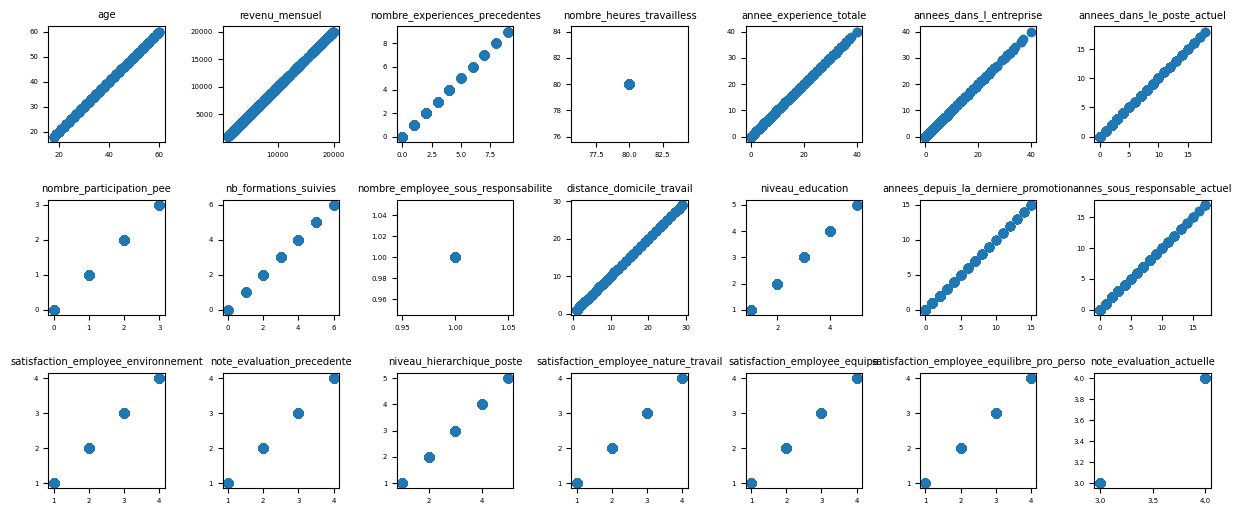

In [27]:
# boxplot ou scatterplot sur toutes les numériqeues
fig, axs = plt.subplots(nrows=3, ncols=7, figsize=(15, 6))

plt.subplots_adjust(wspace=0.5, hspace=0.5)
plt.rcParams["font.size"] = 6

axs[0, 0].scatter(df_brut_join['age'],df_brut_join['age'] )
axs[0, 0].set_title("age")
axs[0, 1].scatter(df_brut_join['revenu_mensuel'],df_brut_join['revenu_mensuel'] )
axs[0, 1].set_title("revenu_mensuel")
axs[0, 2].scatter(df_brut_join['nombre_experiences_precedentes'],df_brut_join['nombre_experiences_precedentes'] )
axs[0, 2].set_title("nombre_experiences_precedentes")
axs[0, 3].scatter(df_brut_join['nombre_heures_travailless'],df_brut_join['nombre_heures_travailless'] )
axs[0, 3].set_title("nombre_heures_travailless")
axs[0, 4].scatter(df_brut_join['annee_experience_totale'],df_brut_join['annee_experience_totale'] )
axs[0, 4].set_title("annee_experience_totale")
axs[0, 5].scatter(df_brut_join['annees_dans_l_entreprise'],df_brut_join['annees_dans_l_entreprise'] )
axs[0, 5].set_title("annees_dans_l_entreprise")
axs[0, 6].scatter(df_brut_join['annees_dans_le_poste_actuel'],df_brut_join['annees_dans_le_poste_actuel'] )
axs[0, 6].set_title("annees_dans_le_poste_actuel")

axs[1, 0].scatter(df_brut_join['nombre_participation_pee'],df_brut_join['nombre_participation_pee'] )
axs[1, 0].set_title("nombre_participation_pee")
axs[1, 1].scatter(df_brut_join['nb_formations_suivies'],df_brut_join['nb_formations_suivies'] )
axs[1, 1].set_title("nb_formations_suivies")
axs[1, 2].scatter(df_brut_join['nombre_employee_sous_responsabilite'],df_brut_join['nombre_employee_sous_responsabilite'] )
axs[1, 2].set_title("nombre_employee_sous_responsabilite")
axs[1, 3].scatter(df_brut_join['distance_domicile_travail'],df_brut_join['distance_domicile_travail'] )
axs[1, 3].set_title("distance_domicile_travail")
axs[1, 4].scatter(df_brut_join['niveau_education'],df_brut_join['niveau_education'] )
axs[1, 4].set_title("niveau_education")
axs[1, 5].scatter(df_brut_join['annees_depuis_la_derniere_promotion'],df_brut_join['annees_depuis_la_derniere_promotion'] )
axs[1, 5].set_title("annees_depuis_la_derniere_promotion")
axs[1, 6].scatter(df_brut_join['annes_sous_responsable_actuel'],df_brut_join['annes_sous_responsable_actuel'] )
axs[1, 6].set_title("annes_sous_responsable_actuel")

axs[2, 0].scatter(df_brut_join['satisfaction_employee_environnement'],df_brut_join['satisfaction_employee_environnement'] )
axs[2, 0].set_title("satisfaction_employee_environnement")
axs[2, 1].scatter(df_brut_join['note_evaluation_precedente'],df_brut_join['note_evaluation_precedente'] )
axs[2, 1].set_title("note_evaluation_precedente")
axs[2, 2].scatter(df_brut_join['niveau_hierarchique_poste'],df_brut_join['niveau_hierarchique_poste'] )
axs[2, 2].set_title("niveau_hierarchique_poste")
axs[2, 3].scatter(df_brut_join['satisfaction_employee_nature_travail'],df_brut_join['satisfaction_employee_nature_travail'] )
axs[2, 3].set_title("satisfaction_employee_nature_travail")
axs[2, 4].scatter(df_brut_join['satisfaction_employee_equipe'],df_brut_join['satisfaction_employee_equipe'] )
axs[2, 4].set_title("satisfaction_employee_equipe")
axs[2, 5].scatter(df_brut_join['satisfaction_employee_equilibre_pro_perso'],df_brut_join['satisfaction_employee_equilibre_pro_perso'] )
axs[2, 5].set_title("satisfaction_employee_equilibre_pro_perso")
axs[2, 6].scatter(df_brut_join['note_evaluation_actuelle'],df_brut_join['note_evaluation_actuelle'] )
axs[2, 6].set_title("note_evaluation_actuelle")

Valeurs abérrantes (outliers).   
2eme verification : le Z-score (+ - 3 ecarts-types)

In [52]:
# Calculs des Z-scores sur toutes les variables numériques
liste_Z_score_numeriques =zscore(df_brut_join[variables_numériques])

# détection des outliers (a +- 2 écarts-types)
df_outliers = liste_Z_score_numeriques.abs() > 3

df_outliers.sum().sort_values(ascending=False) 

annees_depuis_la_derniere_promotion          42
annees_dans_l_entreprise                     25
annee_experience_totale                      16
annes_sous_responsable_actuel                14
annees_dans_le_poste_actuel                  13
id_employee                                   0
satisfaction_employee_equilibre_pro_perso     0
satisfaction_employee_equipe                  0
satisfaction_employee_nature_travail          0
niveau_hierarchique_poste                     0
note_evaluation_precedente                    0
satisfaction_employee_environnement           0
distance_domicile_travail                     0
niveau_education                              0
age                                           0
nombre_employee_sous_responsabilite           0
nb_formations_suivies                         0
nombre_participation_pee                      0
nombre_heures_travailless                     0
nombre_experiences_precedentes                0
revenu_mensuel                          

<table>
  <caption>Interpretation des valeurs abérrantes </caption>
  <thead>
    <tr>
      <th>Varaible</th>
      <th>nombre de valeurs abérrantes</th>
      <th>Valeur min</th>
      <th>Valeur max</th>
      <th>commentaires</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>annees_depuis_la_derniere_promotion</td>
      <td>42</td>
      <td>0</td>
      <td>15</td>
      <td>Valeur max élévée mais possible</td>
    </tr>
    <tr>
      <td>annees_dans_l_entreprise</td>
      <td>25</td>
      <td>0</td>
      <td>40</td>
      <td>Valeur max élévée mais possible</td>
    </tr>
    <tr>
      <td>annee_experience_totale</td>
      <td>16</td>
      <td>0</td>
      <td>40</td>
      <td>Valeurs min/max cohérentes</td>
    </tr>
    <tr>
      <td>annes_sous_responsable_actuel</td>
      <td>14</td>
      <td>0</td>
      <td>17</td>
      <td>Valeur max élevée mais possible</td>
    </tr>
    <tr>
      <td>annees_dans_le_poste_actuel</td>
      <td>13</td>
      <td>0</td>
      <td>18</td>
      <td>Valeur max élevée mais possible </td>
    </tr>
  </tbody>
</table>

Fréquence des variables non numériques

In [22]:
# hist avec etiquette pourcentage ou pie plot avec pourcentage
freq = df_brut_join['genre'].value_counts()
freq_pourcentage = df_brut_join["genre"].value_counts(normalize=True)*100

Text(0.5, 1.0, 'augementation_salaire_precedente')

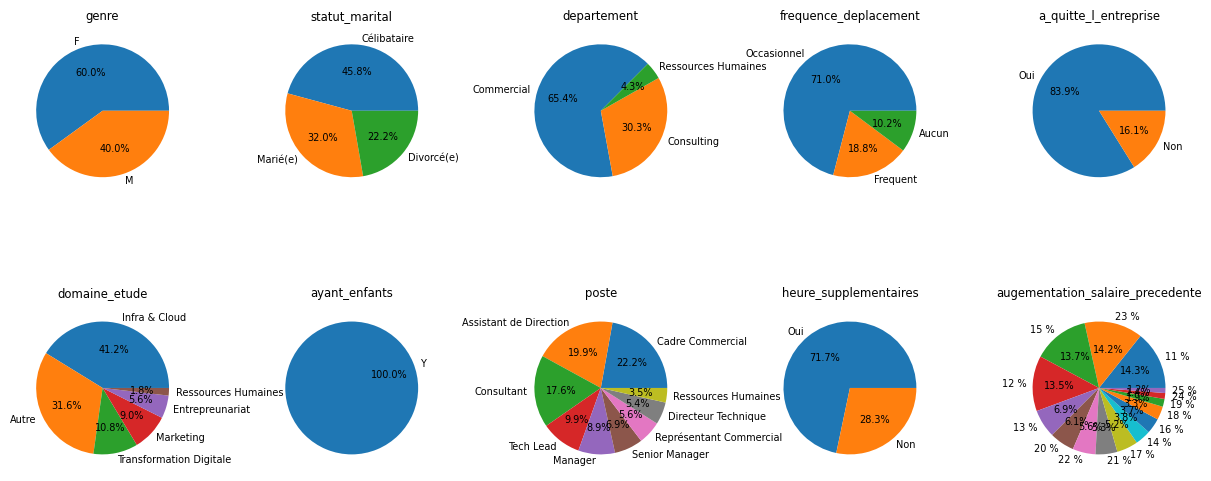

In [23]:
fig, axs = plt.subplots(nrows=2, ncols=5, figsize=(15, 6))

plt.subplots_adjust(wspace=0.5, hspace=0.5)
plt.rcParams["font.size"] = 7


axs[0, 0].pie(df_brut_join['genre'].value_counts(), labels=df_brut_join['genre'].unique(), autopct="%1.1f%%")
axs[0, 0].set_title("genre")
axs[0, 1].pie(df_brut_join['statut_marital'].value_counts(), labels=df_brut_join['statut_marital'].unique(), autopct="%1.1f%%")
axs[0, 1].set_title("statut_marital")
axs[0, 2].pie(df_brut_join['departement'].value_counts(), labels=df_brut_join['departement'].unique(), startangle=45, autopct="%1.1f%%")
axs[0, 2].set_title("departement")
axs[0, 3].pie(df_brut_join['frequence_deplacement'].value_counts(), labels=df_brut_join['frequence_deplacement'].unique(), autopct="%1.1f%%")
axs[0, 3].set_title("frequence_deplacement")
axs[0, 4].pie(df_brut_join['a_quitte_l_entreprise'].value_counts(), labels=df_brut_join['a_quitte_l_entreprise'].unique(), autopct="%1.1f%%")
axs[0, 4].set_title("a_quitte_l_entreprise")

axs[1, 0].pie(df_brut_join['domaine_etude'].value_counts(), labels=df_brut_join['domaine_etude'].unique(), autopct="%1.1f%%")
axs[1, 0].set_title("domaine_etude")
axs[1, 1].pie(df_brut_join['ayant_enfants'].value_counts(), labels=df_brut_join['ayant_enfants'].unique(), startangle= 200 , autopct="%1.1f%%")
axs[1, 1].set_title("ayant_enfants")
axs[1, 2].pie(df_brut_join['poste'].value_counts(), labels=df_brut_join['poste'].unique(), autopct="%1.1f%%")
axs[1, 2].set_title("poste")
axs[1, 3].pie(df_brut_join['heure_supplementaires'].value_counts(), labels=df_brut_join['heure_supplementaires'].unique(), autopct="%1.1f%%")
axs[1, 3].set_title("heure_supplementaires")
axs[1, 4].pie(df_brut_join['augementation_salaire_precedente'].value_counts(), labels=df_brut_join['augementation_salaire_precedente'].unique(), autopct="%1.1f%%")
axs[1, 4].set_title("augementation_salaire_precedente")

Corrélations 

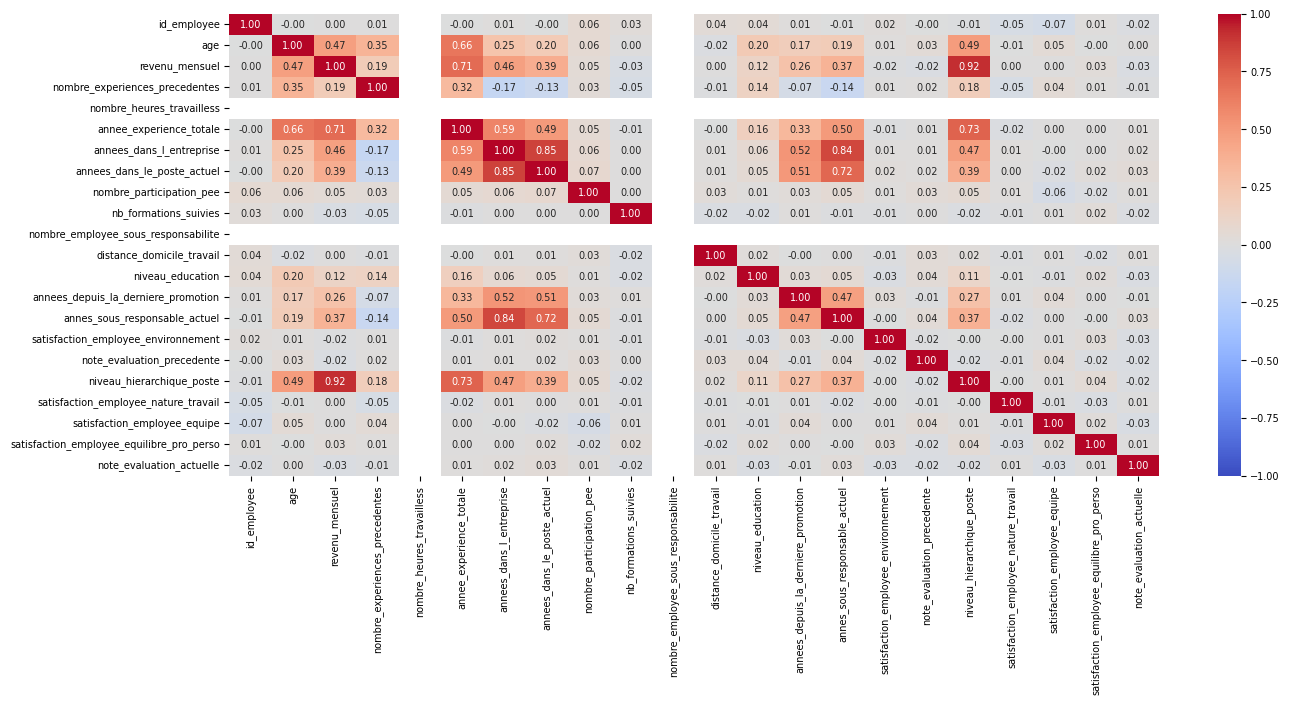

In [25]:
corr_spearman = df_brut_join[variables_numériques].corr(method="spearman")
plt.figure(figsize=(15,6))
sb.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.show()

<table>
  <caption>Les variables corrélées </caption>
  <thead>
    <tr>
      <th>Varaible 1</th>
      <th>Varaible 2</th>
      <th>Score de corrélation</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>annee_experience_totale</td>
      <td>revenu_mensuel</td>
      <td>0.71</td>
    </tr>
    <tr>
      <td>annee_dans_le_poste_actuel</td>
      <td>annees_dans_l_entreprise</td>
      <td>0.85</td>
    </tr>
    <tr>
      <td>annees_dans_l_entreprise</td>
      <td>annee_sous_responsable_actuel</td>
      <td>0.84</td>
    </tr>
    <tr>
      <td>annee_sous_responsable_actuel</td>
      <td>annee_dans_le_poste_actuel</td>
      <td>0.72</td>
    </tr>
    <tr>
      <td>niveau_hiérarchique_poste</td>
      <td>revenu_mensuel</td>
      <td>0.92</td>
    </tr>
    <tr>
      <td>niveau_hiérarchique_poste</td>
      <td>annee_experience_totale</td>
      <td>0.73</td>
    </tr>
  </tbody>
</table>


Colinéarités (variables en relation ex: A = B + C)

### 6 - Nettoyage du dataset joint 

### 7 - Statistiques descriptives du dataset joint

### 8 - Visualisations

### 9 - Synthese de l'EDA